# 02 · Evaluate the G3B clusters

**Before starting.** Run notebook **01 · Train** to completion and keep the same
`experiment_config.json`. Run this notebook from top to bottom. It reuses notebook 01's local dataset and saved models
to measure how the clusters behave on VALIDATION.

| Question | What we use |
|---|---|
| Are groups compact and well separated? | Features and saved assignments → silhouette, DBI, CH |
| How did K and scaling affect grouping? | Pilot comparison, then both full fits |
| Do the groups line up with known security classes? | Saved assignments and known labels → ARI, NMI, class counts |

The first two questions concern **internal geometry**. The last is an **external** check
against known labels. We save the primary model choice before that check.

## 1. Set up the notebook

This first cell reads the thread budget before importing the numeric libraries, just as
in notebook 01. Use the same kernel and folder as the training notebook.

In [2]:
import json
import os
from pathlib import Path

CONFIG_FILE = Path("experiment_config.json")
settings = json.loads(CONFIG_FILE.read_text(encoding="utf-8"))
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[variable] = str(settings["threads"])

The output path combines `output_root` and `experiment_id`. Notebook 01 wrote the pilot and
full models there. The checks below compare the saved configurations, the population
fingerprints, and the model file hashes. A hash is a short fingerprint of a file's bytes.
It helps catch accidental changes between training and evaluation.

In [3]:
import numpy as np
import pandas as pd
from sklearn import config_context
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from threadpoolctl import threadpool_limits

from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

from clustering_utils import (
    best_within_scaling, completed_runs, freeze_json, geometry_record, load_validation_predictions,
    load_validation_sample, open_package, plot_silhouette, read_config, read_json,
    save_analysis, save_composition, save_geometry, save_profiles, write_json,
)

cfg = read_config(CONFIG_FILE)
experiment = Path(cfg["output_root"]) / cfg["experiment_id"]
pilot_dir, full_dir, cache = experiment / "pilot", experiment / "full", experiment / "cache"

In [4]:
if not (full_dir / "run_index.json").is_file():
    raise FileNotFoundError("Run notebook 01 to completion first.")

identity = read_json(full_dir / "package_identity.json")
plan = read_json(pilot_dir / "full_plan.json")
runs = completed_runs(full_dir, cfg, identity, plan["finalists"])
if plan != read_json(full_dir / "input_full_plan.json") or plan["identity"] != identity:
    raise ValueError("The pilot plan does not match the full training run.")
if read_json(cache / "cache_identity.json")["identity"] != identity:
    raise ValueError("The evaluation sample belongs to a different population.")

print("Full models to evaluate", len(runs))

Full models to evaluate 2


## 2. Compare K and scaling from the pilot

Each row is one combination tried in notebook 01. Look at how silhouette changes as K rises
**within the same scaling**. The largest valid silhouette within each scaling gives that
scaling's finalist. Look at observed cluster counts as well. K is what we ask the algorithm
to learn, and a small evaluation sample may show fewer groups.

Raw and standardized features define different distances. Compare how the groups and their
sizes change. Treat the geometry scores as descriptions of their own feature spaces.

In [5]:
pilot_table = pd.read_csv(pilot_dir / "internal_comparison.csv")
display(pilot_table[["scaling", "requested_k", "seed", "observed_clusters_in_eval_sample",
                     "silhouette_mean", "silhouette_sample_std", "selection_eligible"]])

,scaling,requested_k,seed,observed_clusters_in_eval_sample,silhouette_mean,silhouette_sample_std,selection_eligible
0,g3b_standard,2,42,2,0.525235,0.005167,True
1,g3b_standard,4,42,4,0.551646,0.021716,True
2,g3b_standard,8,42,8,0.608706,0.013844,True
3,g3b_standard,12,42,12,0.542216,0.008154,True
4,raw,2,42,2,0.993532,0.001531,True
5,raw,4,42,4,0.996943,0.001685,True
6,raw,8,42,8,0.996414,0.001992,True
7,raw,12,42,11,0.995171,0.001664,True


## 3. Evaluate the geometry after full training

We use the same VALIDATION feature sample for both models. The helper reloads the saved
estimator and checks that its predictions agree with the saved sample assignments. As in
notebook 01, silhouette uses the smaller fixed subsets to bound the distance calculation.
The standard deviation across those subsets describes sampling variation. To study stability
across fits, rerun with multiple training seeds in a separate experiment.

In [6]:
def score_silhouette(X, clusters, item):
    details = []
    for repeat in range(cfg["silhouette_repeats"]):
        positions = np.load(cache / f"silhouette_positions_{repeat}.npy")
        labels = clusters[positions]
        represented = len(np.unique(labels))
        valid = 2 <= represented < len(positions)
        score = float(silhouette_score(X[positions], labels)) if valid else None
        if score is not None and not np.isfinite(score):
            raise ValueError("Non-finite silhouette")
        details.append({
            "run_id": item["run_id"], "repeat": repeat, "rows": len(positions),
            "represented_clusters": represented, "requested_k": item["k"],
            "score": score, "reason": None if valid else "need 2 <= clusters < rows",
        })
    return details

**Silhouette** ranges from −1 to 1, and larger values indicate stronger separation.
**DBI** is lower when clusters are compact relative to the distance between them.
**CH** is higher when between-cluster spread is large relative to within-cluster spread.
They can disagree, because each emphasizes a different property of the geometry.
The table also reports the average squared distance to the assigned centers.

In [7]:
def measure_geometry(stage_dir, runs):
    rows, all_details = [], []
    with threadpool_limits(limits=cfg["threads"]), config_context(working_memory=64):
        for item in runs:
            model, X, clusters = load_validation_sample(cache, stage_dir, item)
            details = score_silhouette(X, clusters, item)
            valid = 2 <= len(np.unique(clusters)) < len(X)
            dbi = float(davies_bouldin_score(X, clusters)) if valid else None
            ch = float(calinski_harabasz_score(X, clusters)) if valid else None
            difference = X - model.cluster_centers_[clusters]
            mean_distance = float(np.einsum("ij,ij->", difference, difference) / len(X))
            rows.append(geometry_record(cfg, stage_dir, item, X, clusters,
                                        details, dbi, ch, mean_distance))
            all_details.extend(details)
    return save_geometry(stage_dir, rows, all_details)

,run_id,geometry_eval_rows,silhouette_mean,silhouette_sample_std,davies_bouldin,calinski_harabasz
0,g3b_standard_k8_seed42,10000,0.432241,0.013217,1.207384,1397.532001
1,raw_k4_seed42,10000,0.988735,0.001386,0.596001,81561.343722


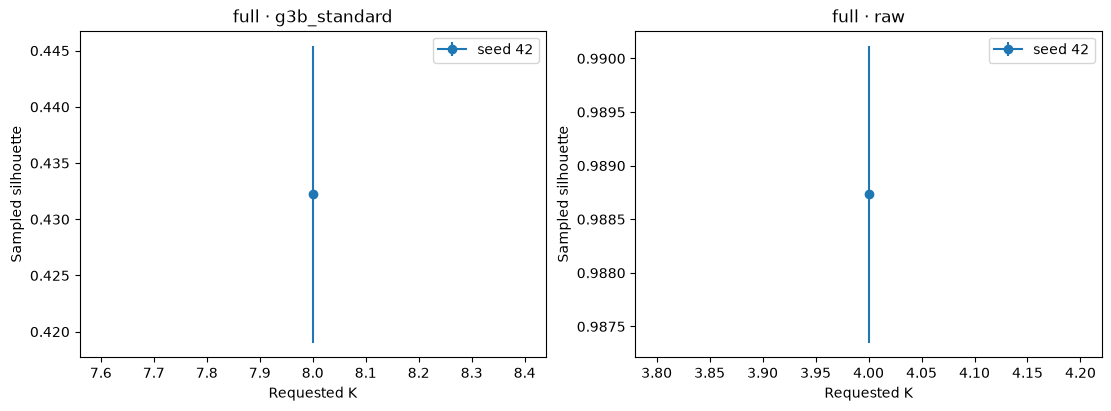

In [8]:
internal = measure_geometry(full_dir, runs)
display(internal[["run_id", "geometry_eval_rows", "silhouette_mean", "silhouette_sample_std",
                  "davies_bouldin", "calinski_harabasz"]])
plot_silhouette(full_dir, internal, cfg["scalings"])

## 4. Record the primary model before looking at labels

The experiment design fixes G3B-standardized features as the primary analysis. The raw run
shows how sensitive the grouping is to scaling. We write the primary choice to
`full/selection.json` now, before opening the known VALIDATION classes. This keeps those
classes from influencing K, scaling, or the choice of model.

In [9]:
primary = best_within_scaling(internal, "g3b_standard")
selection = {
    "identity": identity, "selected_run_id": primary["run_id"],
    "primary_scaling": "g3b_standard", "ground_truth_used": False,
    "rule": "primary scaling fixed in advance; K/seed shortlisted by pilot internal metrics",
    "raw_experiment_role": "sensitivity analysis, not security-label selection",
}
freeze_json(full_dir / "selection.json", selection)
print("Primary model", selection["selected_run_id"])

Primary model g3b_standard_k8_seed42


## 5. Check how clusters relate to known labels

**ARI** compares which pairs of rows belong together in the two partitions. A perfect
agreement scores 1, agreement near chance scores around 0, and worse-than-chance agreement
can score below 0. **NMI** measures how much knowing a row's cluster tells you about its
class. It ranges from 0 to 1, with larger values meaning more shared information.

These scores ignore the numbering of cluster IDs. Imagine swapping the names of clusters
0 and 1. The grouping stays the same, so ARI and NMI stay the same. They measure agreement
between partitions and have a different meaning from classifier accuracy.

We use all VALIDATION labels for this step after verifying the data matches the saved
population. The configured labels are `0` for benign and `1` for malicious by default.

In [10]:
package, current_identity = open_package(cfg)
if current_identity != identity:
    raise ValueError("Package population changed since training.")

_unused_X, y_validation, _unused_metadata = package.load("VALIDATION")
label_values = (cfg["benign_label"], cfg["malicious_label"])
if set(np.unique(y_validation).tolist()) != set(label_values):
    raise ValueError("Unexpected labels. Check the G3B binary label contract.")
prevalence = float(np.mean(y_validation == cfg["malicious_label"]))
print("Overall malicious fraction", f"{prevalence:.2%}")

Overall malicious fraction 92.10%


For each run we also make a **cluster composition** table with one row per cluster and
one count per class. `classes == label` creates a Boolean mask selecting rows of a class.
`np.bincount` tallies their cluster IDs. Using one batch at a time keeps these counts
small in memory, even when VALIDATION has about a million records.

In [11]:
def count_classes_by_cluster(clusters, k):
    counts = np.zeros((k, 2), dtype=np.int64)
    for start in range(0, len(clusters), cfg["batch_size"]):
        end = start + cfg["batch_size"]
        group_ids = clusters[start:end]
        classes = y_validation[start:end]
        for column, label in enumerate(label_values):
            counts[:, column] += np.bincount(group_ids[classes == label], minlength=k)
    return counts

**Malicious fraction** divides the malicious count by the cluster's total. **Lift** divides
that fraction by the malicious fraction across all VALIDATION. For example, 60% malicious
in a cluster and 30% overall gives a lift of 2. Always check the row count alongside lift.
A small cluster offers less evidence about a broader pattern.

In [12]:
external_rows = []
for item in runs:
    run_dir = full_dir / item["run_id"]
    clusters = load_validation_predictions(run_dir, len(y_validation))
    with threadpool_limits(limits=cfg["threads"]):
        ari = float(adjusted_rand_score(y_validation, clusters))
        nmi = float(normalized_mutual_info_score(y_validation, clusters, average_method="arithmetic"))

    counts = count_classes_by_cluster(clusters, item["k"])
    composition = save_composition(run_dir, counts, prevalence)
    external_rows.append({
        "run_id": item["run_id"], "ari": ari, "nmi": nmi,
        "external_eval_rows": len(y_validation), "external_scope": "entire VALIDATION, post-selection",
        "overall_malicious_fraction": prevalence,
    })
    print(item["run_id"])
    display(composition)

g3b_standard_k8_seed42


,benign_count,malicious_count,total,malicious_fraction,benign_fraction,malicious_lift_vs_validation
cluster_id,,,,,,
0,4279,351918,356197,0.987987,0.012013,1.072713
1,4703,905,5608,0.161377,0.838623,0.175216
2,94,110,204,0.539216,0.460784,0.585457
3,65991,619844,685835,0.903780,0.096220,0.981284
4,3012,0,3012,0.000000,1.000000,0.000000
5,496,0,496,0.000000,1.000000,0.000000
6,68,106,174,0.609195,0.390805,0.661437
7,4792,54,4846,0.011143,0.988857,0.012099


raw_k4_seed42


,benign_count,malicious_count,total,malicious_fraction,benign_fraction,malicious_lift_vs_validation
cluster_id,,,,,,
0,82970,948657,1031627,0.919574,0.080426,0.998432
1,89,129,218,0.591743,0.408257,0.642489
2,317,1901,2218,0.857078,0.142922,0.930578
3,59,22250,22309,0.997355,0.002645,1.082884


In [13]:
write_json(full_dir / "external_metrics.json", external_rows)
comparison = internal.merge(pd.DataFrame(external_rows), on="run_id", validate="one_to_one")
comparison.to_csv(full_dir / "comparison.csv", index=False)
display(comparison[["run_id", "requested_k", "silhouette_mean", "ari", "nmi", "external_eval_rows"]])

,run_id,requested_k,silhouette_mean,ari,nmi,external_eval_rows
0,g3b_standard_k8_seed42,8,0.432241,0.007821,0.091792,1056372
1,raw_k4_seed42,4,0.988735,-0.025312,0.008262,1056372


## 6. Explain what the clusters show

The **stacked bars** show the class mix inside each primary cluster. The **heatmap** shows
the eight feature positions whose center coordinates vary most across clusters. Each row
is a cluster center. Positive coordinates are above the TRAIN mean for that feature.
Use the G3B feature contract to match positions to names before describing a network behavior.

The saved `analysis.md` fills in the measured numbers. To finish the project write-up,
describe two observed clusters with their counts, class fractions, and named features.
Compare each class fraction with the overall baseline. Relate the pilot table to your K
and scaling discussion.

If geometry scores look strong but ARI and NMI are low, the model may be finding structure
such as traffic volume or device behavior that crosses the benign/malicious boundary. Confirm
such an interpretation with the feature contract and appropriate data. K-Means favors compact
Euclidean groups, is sensitive to outliers and scaling, and assigns even unusual records to a
center. Uniform samples can miss rare groups.

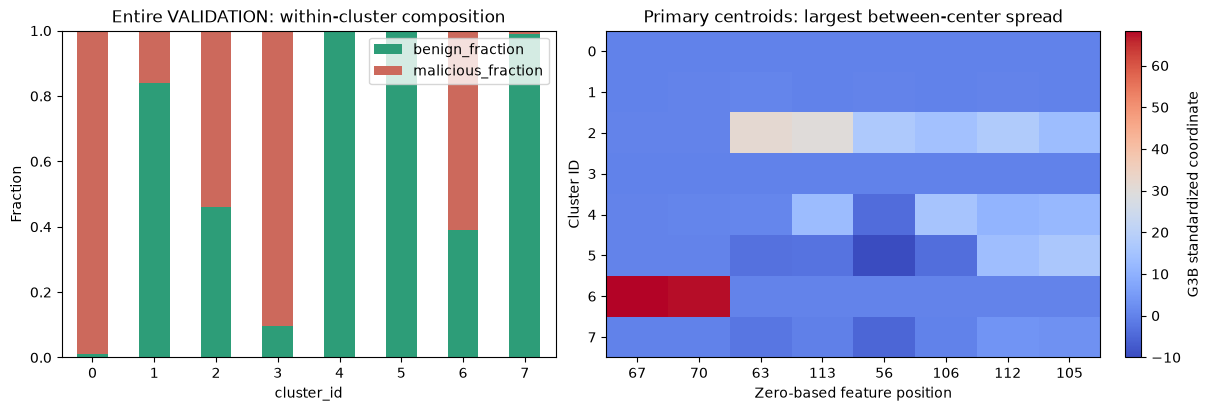

# Clustering experiment: measured validation analysis

Primary run: g3b_standard_k8_seed42. Protocol: g3b_unsupervised_v1_proposal.
All 115 ordered G3B numeric predictors were used. Labels, source identity and device strings
were excluded from fitting. The complete TRAIN population (4,944,968 rows)
was processed for 2 epochs with batch size 4096.
Standardization reused G3B's TRAIN-only scaler. TEST was not opened.

## Experiment design and selection
The pilot compared K=[2, 4, 8, 12] for both G3B standardization and raw features, using the
same 100,000-row uniform TRAIN sample and seed(s) [42].
It shortlisted one K per scaling using internal VALIDATION silhouette only. Each finalist was then
trained on all TRAIN rows. Standardized geometry was the primary analysis by prior policy.
The selection was saved before any ground-truth validation labels were inspected.
This is a separate unsupervised protocol proposal, not a classifier macro-F1 result schema.

## Internal geometry
The primary 

In [14]:
primary_composition = save_profiles(full_dir, selection["selected_run_id"])
report = save_analysis(full_dir, cfg, selection, comparison, primary_composition)
print(report)

### Files to hand over

- **K and scaling** · `pilot/internal_comparison.csv` and `pilot/silhouette_by_k.png`
- **Metrics** · `full/comparison.csv`, `full/silhouette_sampling_details.json`,
  and `full/external_metrics.json`
- **Cluster interpretation** · `full/cluster_interpretation.png`,
  `full/<run_id>/cluster_composition_validation.csv`, and `full/analysis.md`
- **Reproducibility** · Keep the configuration, the saved model and assignments, and the
  training logs. Follow **START_HERE.md** to replay the assignments from disk.